# Predictive Maintenance: Multiclass Random Forest

**Question.** From five sensor readings and the machine's quality grade, can we tell not just *whether* a machine is about to fail, but *how*? The five failure modes are heat dissipation, power, overstrain, tool wear and random.

**Why the failure mode matters.** Each mode has a different fix: cooling, load management, tool replacement. A binary "failure" alert tells maintenance something is wrong; a typed alert tells them what to do.

**Approach**
1. Data audit: class imbalance and label consistency
2. EDA by failure mode
3. Baseline decision tree and random forest on the 6-class target
4. Random forest tuning with macro-F1 scoring and class weighting
5. Extension: physics-informed features (mechanical power, temperature difference, tool strain)
6. Per-class reliability and conclusion

## 1. Setup and Data Audit

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score, precision_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
RANDOM_STATE = 42
FIG_DIR, MET_DIR = Path('../outputs/figures'), Path('../outputs/metrics')
FIG_DIR.mkdir(parents=True, exist_ok=True); MET_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid'); plt.rcParams.update({'figure.dpi': 110})

In [2]:
raw = pd.read_csv('../data/machine_maintenance.csv', encoding='utf-8-sig', index_col='Product ID')
print('Shape:', raw.shape, '| missing:', int(raw.isna().sum().sum()), '| duplicates:', raw.duplicated().sum())
display(raw.head())
display(raw['Failure Type'].value_counts().to_frame('Count').assign(Share=lambda d: (d['Count'] / len(raw)).round(4)))

Shape: (10000, 8) | missing: 0 | duplicates: 0


,Type,Air Temp [K],Process Temp [K],Rotational Speed [rpm],Torque [Nm],Tool wear [min],Failure,Failure Type
Product ID,,,,,,,,
M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


,Count,Share
Failure Type,,
No Failure,9652,0.9652
Heat Dissipation Failure,112,0.0112
Power Failure,95,0.0095
Overstrain Failure,78,0.0078
Tool Wear Failure,45,0.0045
Random Failures,18,0.0018


**Observation:** 10,000 machine records, with no missing values or duplicates. Failures are rare: 96.5% of rows are 'No Failure', and the five failure modes range from 112 rows (heat dissipation) down to 18 (random failures).

In [3]:
# Label consistency: the binary flag and the failure type should agree
display(pd.crosstab(raw['Failure Type'], raw['Failure'], margins=True))

Failure,0,1,All
Failure Type,,,
Heat Dissipation Failure,0,112,112
No Failure,9643,9,9652
Overstrain Failure,0,78,78
Power Failure,0,95,95
Random Failures,18,0,18
Tool Wear Failure,0,45,45
All,9661,339,10000


**Observation:** 27 rows (0.3%) contradict themselves. Nine are flagged `Failure = 1` with type 'No Failure', and all 18 'Random Failures' are flagged `Failure = 0`. The multiclass models use `Failure Type` as the label, so the random-failure rows still count as failures there.

## 2. Data Preparation and EDA
Physics-based features are added at this point for EDA only. The baseline models in Section 3 use the six raw inputs, so the effect of the engineered features can be measured separately in Section 5.
- **Power [W]** = torque x angular speed = Torque x RPM x 2π / 60
- **Temperature difference [K]** = process temperature - air temperature
- **Strain [min·Nm]** = tool wear x torque

In [4]:
data = raw.copy()
# 27 rows whose binary flag contradicts the type are kept with their Failure Type label; see the audit observation.
data['Power [W]'] = data['Torque [Nm]'] * data['Rotational Speed [rpm]'] * 2 * np.pi / 60
data['Temp diff [K]'] = data['Process Temp [K]'] - data['Air Temp [K]']
data['Strain [min*Nm]'] = data['Tool wear [min]'] * data['Torque [Nm]']
data['Type'] = data['Type'].map({'L': 0, 'M': 1, 'H': 2})   # quality grade: Low < Medium < High
RAW_FEATS = ['Type', 'Air Temp [K]', 'Process Temp [K]', 'Rotational Speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
ENG_FEATS = RAW_FEATS + ['Power [W]', 'Temp diff [K]', 'Strain [min*Nm]']
CLASSES = ['No Failure', 'Heat Dissipation Failure', 'Power Failure', 'Overstrain Failure', 'Tool Wear Failure', 'Random Failures']
SHORT = {'No Failure': 'None', 'Heat Dissipation Failure': 'Heat', 'Power Failure': 'Power', 'Overstrain Failure': 'Overstrain',
         'Tool Wear Failure': 'Tool wear', 'Random Failures': 'Random'}
display(data.groupby('Failure Type')[ENG_FEATS[1:]].median().reindex(CLASSES).round(1))

,Air Temp [K],Process Temp [K],Rotational Speed [rpm],Torque [Nm],Tool wear [min],Power [W],Temp diff [K],Strain [min*Nm]
Failure Type,,,,,,,,
No Failure,300.0,310.0,1507.0,39.9,107.0,6243.5,9.8,3952.2
Heat Dissipation Failure,302.4,310.7,1346.0,52.4,106.0,7298.9,8.3,5549.6
Power Failure,300.4,310.2,1386.0,63.6,100.0,9100.4,9.7,3608.8
Overstrain Failure,299.4,310.1,1362.5,56.8,207.0,8088.5,10.2,11545.4
Tool Wear Failure,300.4,310.3,1521.0,37.7,215.0,5986.9,9.6,7843.2
Random Failures,300.8,311.1,1490.0,44.6,142.0,6915.1,9.7,5645.4


**Observation:** Each failure mode has a distinct signature. Heat failures combine a small process-air temperature gap (8.3 K vs 9.8 K) with low speed (1,346 rpm). Power failures have the highest mechanical power (9,100 W vs 6,244 W). Overstrain failures have very high strain (11,545 min·Nm vs 3,952). Tool-wear failures occur at high tool wear (215 min) but otherwise look normal, and random failures look like normal operation.

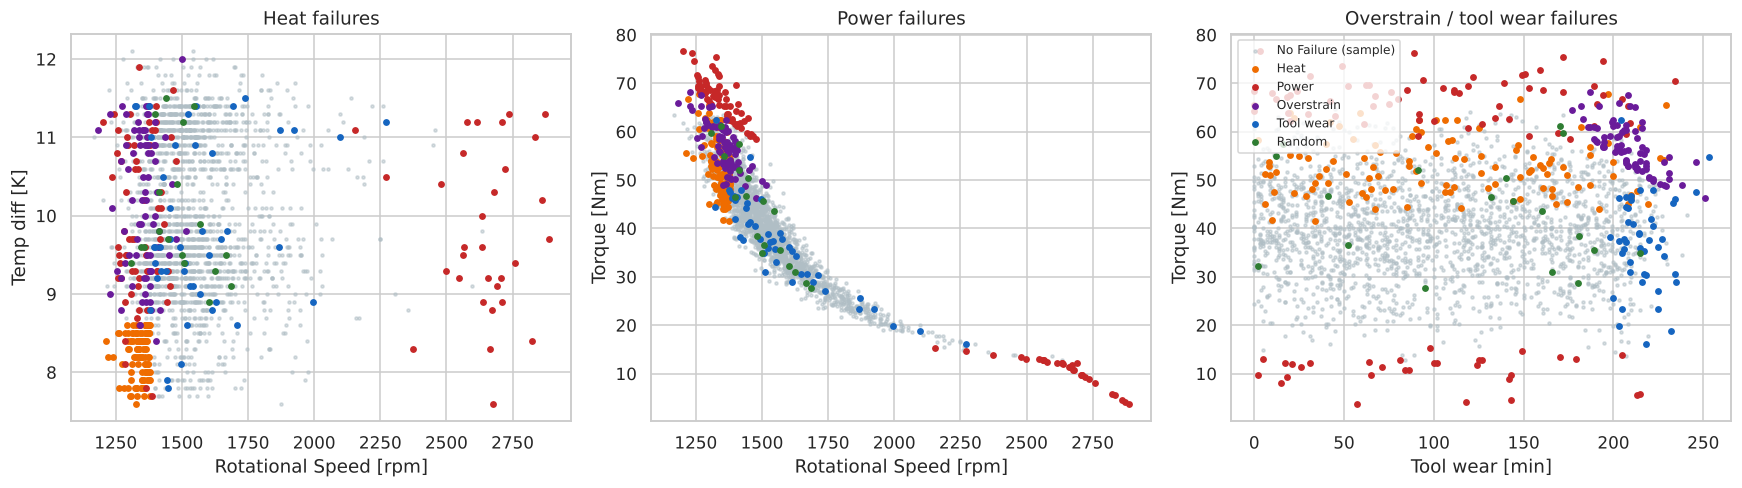

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
pal = dict(zip(CLASSES, ['#B0BEC5', '#EF6C00', '#C62828', '#6A1B9A', '#1565C0', '#2E7D32']))
pairs = [('Rotational Speed [rpm]', 'Temp diff [K]', 'Heat'), ('Rotational Speed [rpm]', 'Torque [Nm]', 'Power'),
         ('Tool wear [min]', 'Torque [Nm]', 'Overstrain / tool wear')]
for ax, (xc, yc, ttl) in zip(axes, pairs):
    nf = data[data['Failure Type'] == 'No Failure'].sample(2000, random_state=RANDOM_STATE)
    ax.scatter(nf[xc], nf[yc], s=4, color=pal['No Failure'], alpha=0.5, label='No Failure (sample)')
    for c in CLASSES[1:]:
        sub = data[data['Failure Type'] == c]; ax.scatter(sub[xc], sub[yc], s=12, color=pal[c], label=SHORT[c])
    ax.set_xlabel(xc); ax.set_ylabel(yc); ax.set_title(f'{ttl} failures')
axes[2].legend(fontsize=8, loc='upper left')
plt.tight_layout(); plt.savefig(FIG_DIR / 'failure_modes_feature_space.png', bbox_inches='tight'); plt.show()

**Observation:** In raw feature space, heat failures sit in a low-speed corner, power failures lie along the high-torque/low-speed and low-torque/high-speed edges, and overstrain failures form a band where tool wear *and* torque are both high. Each boundary is a combination of two features: a difference, a product or a ratio. That is a hint for Section 5.

In [6]:
X_raw, X_eng, y = data[RAW_FEATS], data[ENG_FEATS], data['Failure Type']
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_raw, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
X_train_eng, X_test_eng = X_eng.loc[X_train_raw.index], X_eng.loc[X_test_raw.index]
display(pd.DataFrame({'Train': y_train.value_counts(), 'Test': y_test.value_counts()}).reindex(CLASSES))

,Train,Test
Failure Type,,
No Failure,6756,2896
Heat Dissipation Failure,78,34
Power Failure,67,28
Overstrain Failure,55,23
Tool Wear Failure,31,14
Random Failures,13,5


## 3. Baseline Models
**Primary metric: macro-F1.** It weights every failure mode equally. With 96.5% of rows labelled "No Failure", accuracy is uninformative: predicting "No Failure" every time scores 96.5%. Per-class recall is reported alongside, because a missed failure (false negative) is the costly error.

In [7]:
def evaluate(name, model, Xtr, Xte):
    ptr, pte = model.predict(Xtr), model.predict(Xte)
    row = {'Model': name, 'Train macro-F1': f1_score(y_train, ptr, average='macro'), 'Test macro-F1': f1_score(y_test, pte, average='macro'),
           'Test accuracy': accuracy_score(y_test, pte), 'Test balanced accuracy': balanced_accuracy_score(y_test, pte)}
    rec = recall_score(y_test, pte, labels=CLASSES, average=None, zero_division=0)
    row.update({f'Recall: {SHORT[c]}': r for c, r in zip(CLASSES, rec)})
    return row, pte

results, preds = [], {}
always_none = np.array(['No Failure'] * len(y_test))
results.append({'Model': 'Always "No Failure"', 'Test macro-F1': f1_score(y_test, always_none, average='macro'),
                'Test accuracy': accuracy_score(y_test, always_none), 'Test balanced accuracy': balanced_accuracy_score(y_test, always_none)})
dt = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train_raw, y_train)
r, preds['dt'] = evaluate('Decision tree (raw)', dt, X_train_raw, X_test_raw); results.append(r)
rf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_raw, y_train)
r, preds['rf'] = evaluate('Random forest, default (raw)', rf, X_train_raw, X_test_raw); results.append(r)
print(f'Decision tree: depth {dt.get_depth()}, {dt.get_n_leaves()} leaves')
display(pd.DataFrame(results).set_index('Model').round(3))

Decision tree: depth 20, 164 leaves


,Test macro-F1,Test accuracy,Test balanced accuracy,Train macro-F1,Recall: None,Recall: Heat,Recall: Power,Recall: Overstrain,Recall: Tool wear,Recall: Random
Model,,,,,,,,,,
"Always ""No Failure""",0.164,0.965,0.167,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Decision tree (raw),0.549,0.975,0.545,1.0,0.987,0.912,0.750,0.478,0.143,0.0
"Random forest, default (raw)",0.521,0.980,0.485,1.0,0.997,0.706,0.643,0.565,0.000,0.0


**Observation:** Accuracy is misleading here. Always predicting 'No Failure' scores 96.5% accuracy but 0.164 macro-F1. The fully grown decision tree (depth 20, 164 leaves) reaches macro-F1 0.549; the default random forest reaches only 0.521, while recalling heat failures 71% of the time. Neither detects tool-wear or random failures. Both score 1.000 on training data, so both overfit.

## 4. Random Forest Tuning (raw features)

In [8]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
param_grid = {'n_estimators': [200], 'max_depth': [None, 12], 'min_samples_leaf': [1, 3],
              'max_features': ['sqrt', None], 'class_weight': [None, 'balanced_subsample']}
grid_raw = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1), param_grid, scoring='f1_macro', cv=cv, n_jobs=-1)
grid_raw.fit(X_train_raw, y_train)
print('Best parameters:', grid_raw.best_params_, f'| CV macro-F1 {grid_raw.best_score_:.3f}')
r, preds['rf_tuned_raw'] = evaluate('Random forest, tuned (raw)', grid_raw.best_estimator_, X_train_raw, X_test_raw); results.append(r)
display(pd.DataFrame(results).set_index('Model').round(3))

Best parameters: {'class_weight': 'balanced_subsample', 'max_depth': 12, 'max_features': None, 'min_samples_leaf': 3, 'n_estimators': 200} | CV macro-F1 0.549


,Test macro-F1,Test accuracy,Test balanced accuracy,Train macro-F1,Recall: None,Recall: Heat,Recall: Power,Recall: Overstrain,Recall: Tool wear,Recall: Random
Model,,,,,,,,,,
"Always ""No Failure""",0.164,0.965,0.167,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Decision tree (raw),0.549,0.975,0.545,1.000,0.987,0.912,0.750,0.478,0.143,0.0
"Random forest, default (raw)",0.521,0.980,0.485,1.000,0.997,0.706,0.643,0.565,0.000,0.0
"Random forest, tuned (raw)",0.555,0.959,0.610,0.846,0.968,0.794,0.786,0.826,0.286,0.0


**Observation:** Tuning picks class weighting (`balanced_subsample`), depth 12 and all features per split. Test macro-F1 rises only slightly (0.555), but the recall pattern changes: overstrain recall goes from 57% to 83% and tool-wear recall from 0% to 29%. The cost is many more false alarms, so accuracy falls to 95.9%. With raw features, class weighting mostly moves errors around.

## 5. Extension: Physics-Informed Features
Heat-dissipation failures depend on the *difference* between process and air temperature at low speed. Power failures depend on mechanical power (torque x speed). Overstrain depends on tool wear *times* torque. A tree must approximate each product or difference with many axis-aligned splits. Supplying the three derived features directly lets a single split express the rule.

In [9]:
grid_eng = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1), param_grid, scoring='f1_macro', cv=cv, n_jobs=-1)
grid_eng.fit(X_train_eng, y_train)
print('Best parameters:', grid_eng.best_params_, f'| CV macro-F1 {grid_eng.best_score_:.3f}')
best = grid_eng.best_estimator_
r, preds['rf_tuned_eng'] = evaluate('Random forest, tuned (+ physics features)', best, X_train_eng, X_test_eng); results.append(r)
res_df = pd.DataFrame(results).set_index('Model').round(3)
display(res_df)
res_df.to_csv(MET_DIR / 'model_comparison_test.csv')

Best parameters: {'class_weight': None, 'max_depth': None, 'max_features': None, 'min_samples_leaf': 1, 'n_estimators': 200} | CV macro-F1 0.654


,Test macro-F1,Test accuracy,Test balanced accuracy,Train macro-F1,Recall: None,Recall: Heat,Recall: Power,Recall: Overstrain,Recall: Tool wear,Recall: Random
Model,,,,,,,,,,
"Always ""No Failure""",0.164,0.965,0.167,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Decision tree (raw),0.549,0.975,0.545,1.000,0.987,0.912,0.750,0.478,0.143,0.0
"Random forest, default (raw)",0.521,0.980,0.485,1.000,0.997,0.706,0.643,0.565,0.000,0.0
"Random forest, tuned (raw)",0.555,0.959,0.610,0.846,0.968,0.794,0.786,0.826,0.286,0.0
"Random forest, tuned (+ physics features)",0.647,0.992,0.661,1.000,0.998,0.971,1.000,1.000,0.000,0.0


**Observation:** Adding three physics features lifts CV macro-F1 from 0.549 to 0.654 and test macro-F1 to **0.647**, with 99.2% accuracy. Recall reaches **97% for heat, 100% for power and 100% for overstrain failures**. This version prefers no class weighting: once the features describe the failure mechanisms directly, rebalancing is no longer needed.

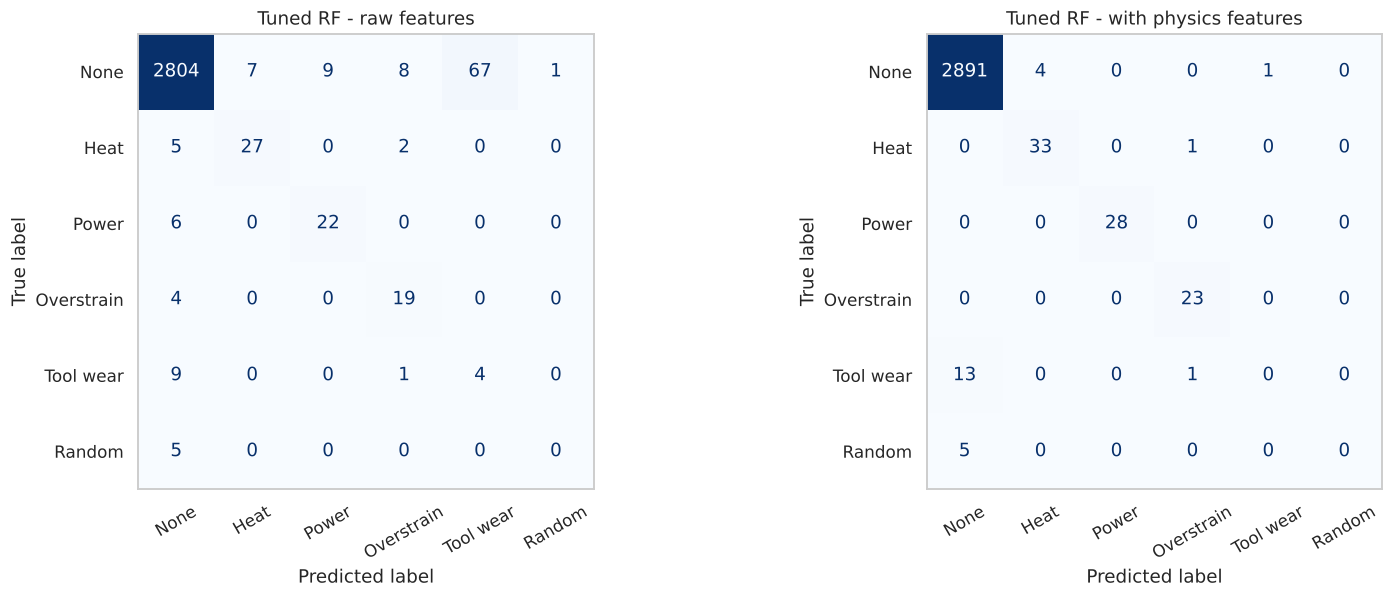

                          precision    recall  f1-score   support

              No Failure      0.994     0.998     0.996      2896
Heat Dissipation Failure      0.892     0.971     0.930        34
           Power Failure      1.000     1.000     1.000        28
      Overstrain Failure      0.920     1.000     0.958        23
       Tool Wear Failure      0.000     0.000     0.000        14
         Random Failures      0.000     0.000     0.000         5

                accuracy                          0.992      3000
               macro avg      0.634     0.661     0.647      3000
            weighted avg      0.986     0.992     0.989      3000



In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
for ax, (k, ttl) in zip(axes, [('rf_tuned_raw', 'Tuned RF - raw features'), ('rf_tuned_eng', 'Tuned RF - with physics features')]):
    cm = confusion_matrix(y_test, preds[k], labels=CLASSES)
    ConfusionMatrixDisplay(cm, display_labels=[SHORT[c] for c in CLASSES]).plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=30)
    ax.set_title(ttl); ax.grid(False)
plt.tight_layout(); plt.savefig(FIG_DIR / 'confusion_raw_vs_physics.png', bbox_inches='tight'); plt.show()
print(classification_report(y_test, preds['rf_tuned_eng'], labels=CLASSES, digits=3, zero_division=0))

**Observation:** The remaining errors are almost entirely tool-wear and random failures, at 0% recall each. Tool-wear failures happen at a random point between about 200 and 240 minutes of wear: 790 machines are in that window, but only 45 fail. Random failures are random by construction. No sensor feature can predict them, so the practical ceiling for macro-F1 here is about 4/6 ≈ 0.67, and the model is close to it.

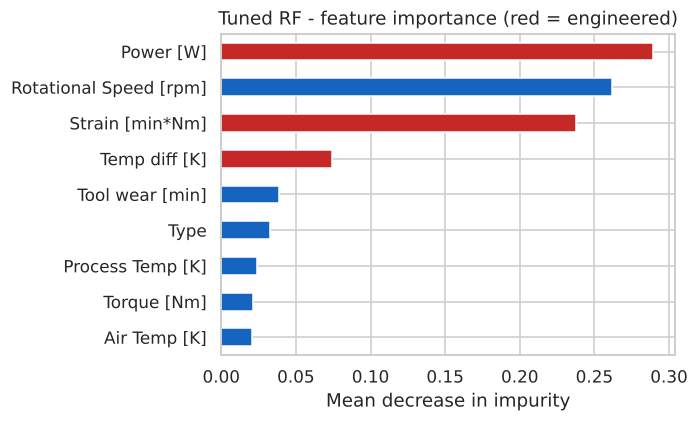

In [11]:
imp = pd.Series(best.feature_importances_, index=ENG_FEATS).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 4)); imp.plot.barh(ax=ax, color=['#C62828' if f in ENG_FEATS[6:] else '#1565C0' for f in imp.index])
ax.set_title('Tuned RF - feature importance (red = engineered)'); ax.set_xlabel('Mean decrease in impurity')
plt.tight_layout(); plt.savefig(FIG_DIR / 'feature_importance_physics.png', bbox_inches='tight'); plt.show()
imp.sort_values(ascending=False).round(3).to_csv(MET_DIR / 'feature_importance_physics.csv')

**Observation:** The three engineered features account for 60% of total importance: power (0.29), strain (0.24) and temperature difference (0.07). Rotational speed (0.26) stays important because it enters both the heat-failure rule and the power calculation. The raw torque and temperature columns become nearly redundant.

## 6. Binary View: Would a Maintenance Team Get the Alert?
Collapsing predictions to failure / no failure shows how many real failures produce *some* alert, even when the mode is wrong.

In [12]:
bin_rows = {}
for k, name in [('rf', 'Default RF (raw)'), ('rf_tuned_raw', 'Tuned RF (raw)'), ('rf_tuned_eng', 'Tuned RF (+ physics)')]:
    yt, yp = (y_test != 'No Failure').astype(int), (pd.Series(preds[k], index=y_test.index) != 'No Failure').astype(int)
    bin_rows[name] = {'Failures caught (recall)': recall_score(yt, yp), 'Alert precision': precision_score(yt, yp),
                      'False alarms': int(((yp == 1) & (yt == 0)).sum()), 'Missed failures': int(((yp == 0) & (yt == 1)).sum())}
bin_df = pd.DataFrame(bin_rows).T
display(bin_df.round(3))
bin_df.to_csv(MET_DIR / 'binary_alert_view.csv')

,Failures caught (recall),Alert precision,False alarms,Missed failures
Default RF (raw),0.558,0.853,10.0,46.0
Tuned RF (raw),0.721,0.449,92.0,29.0
Tuned RF (+ physics),0.827,0.945,5.0,18.0


**Observation:** As a maintenance alert system, the physics-feature model catches **82.7% of failures** (86 of 104) with **94.5% alert precision**: only 5 false alarms in 3,000 machines. The tuned raw-feature model catches fewer failures (72.1%) while raising 92 false alarms. Domain knowledge improved both detection and alert quality, which a hyperparameter search alone did not.

# Conclusion

| Test set (3,000 machines) | Macro-F1 | Heat | Power | Overstrain | Tool wear | Random | Alert precision |
|---|---|---|---|---|---|---|---|
| Default random forest | 0.521 | 71% | 64% | 57% | 0% | 0% | 0.853 |
| Tuned RF, raw features | 0.555 | 79% | 79% | 83% | 29% | 0% | 0.449 |
| Tuned RF + physics features | **0.647** | **97%** | **100%** | **100%** | 0% | 0% | **0.945** |

**Findings**
1. Three physically meaningful features (power, temperature difference, strain) improved the model more than any hyperparameter, raising macro-F1 from 0.555 to 0.647 and cutting false alarms from 92 to 5.
2. The three deterministic failure modes are now detected almost perfectly.
3. Tool-wear and random failures are not predictable from these sensors. For tool wear, the right operational answer is scheduled tool replacement before about 200 minutes, not a model.

**Limitations:** The AI4I 2020 dataset is synthetic, and its failure rules are simple, which flatters the physics features. Minority classes are small (5-34 test cases), so per-class recall is noisy. 27 labels are internally inconsistent.